# BIL545 · Proje 2 · Beijing PM2.5 kirlilik epizotları

**Grup adı:** Grup 03
**Üyeler:** Süleyman Balsak (254312022) · Seda Erten (254312008) · İlkin Urcan (244329078) · Aslıhan Semiz Varlı (254329024)
**İletişim sorumlusu:** Süleyman Balsak
**Konu:** 9.7 Hava kalitesi ve kirlilik epizotları · **Veri:** UCI Beijing PM2.5 (PRSA, 2010–2014, saatlik)
**Girdi:** Proje 1'in temizlenmiş verisi, değerlendirme hattı (dokunulmayan 2014 test dönemi, `TimeSeriesSplit(5, gap=24)`) ve en iyi modeli (rastgele orman).

## 0. Hazırlık

In [1]:
import sys
import warnings
import numpy as np
import pandas as pd
import sklearn
import scipy
import matplotlib
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (f1_score, balanced_accuracy_score, accuracy_score, recall_score,
                             confusion_matrix, adjusted_rand_score, silhouette_score)

print("=== KÜTÜPHANE SÜRÜMLERİ ===")
print(f"Python       : {sys.version.split()[0]}")
print(f"Pandas       : {pd.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"Scikit-learn : {sklearn.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")

SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
print("\nRastgelelik tohumu (SEED) 42 olarak sabitlendi.")

=== KÜTÜPHANE SÜRÜMLERİ ===
Python       : 3.13.18
Pandas       : 2.2.3
NumPy        : 2.4.6
Scikit-learn : 1.6.1
SciPy        : 1.16.3
Matplotlib   : 3.10.0

Rastgelelik tohumu (SEED) 42 olarak sabitlendi.


### Okuma notları
- **Ben-Hur, Elisseeff ve Guyon (2002), A stability based method for discovering structure in clustered data:** Verinin iki rastgele alt örneklemini aynı k ile kümeleyip ortak noktalarda iki etiketlemenin benzerliğini ölçüyorlar; bunu birçok çift için tekrarlayıp benzerliğin dağılımına bakıyorlar. Verideki gerçek yapıya uyan k'da dağılım 1'e yığılır, k gerçek yapıyı aştıkça kümelemeler rastgele bölünmeye başlar ve dağılım yayılır. 1.2'de bu yöntemi ARI ile uyguladık ve dağılımın hem ortalamasını hem genişliğini (ortalama − std) seçim ölçütü yaptık.
- **Liu, Ting ve Zhou (2008), Isolation forest:** Aykırı gözlemler "az ve farklı" olduğu için rastgele öznitelik ve rastgele eşikle yapılan bölmelerde diğerlerinden çok daha erken yalıtılırlar. Aykırılık skoru, bir noktayı yalıtmak için gereken ortalama yol uzunluğundan hesaplanır; küçük alt örneklemlerle kurulan ağaçlar hem hızlıdır hem de yoğun aykırı gruplarının birbirini gizlemesini azaltır. Uzaklık ya da yoğunluk hesabı yapmaz; bu yüzden LOF gibi yerel yoğunluğa dayanan bir yöntemle karşılaştırmak (2.1) iki farklı aykırılık tanımını yan yana koymak demektir.
- **Mehrabi vd. (2021), A survey on bias and fairness in machine learning:** Makine öğrenmesindeki yanlılık kaynaklarını (temsil ve örnekleme yanlılığı, ölçüm yanlılığı, tarihsel yanlılık, değerlendirme yanlılığı) ve adillik tanımlarını (demografik eşitlik, eşitlenmiş olasılıklar, fırsat eşitliği) derliyor. Verimizde kişi bilgisi olmadığı için adillik değil alt grup analizi yapıyoruz, ama iki kavram doğrudan geçerli: **ölçüm yanlılığı** (hedef tek bir istasyonun ölçümü ve eşikle tanımlanmış bir vekil) ve **değerlendirme yanlılığı** (tek bir ortalama skor, alt gruplardaki farkları gizleyebilir). Bölüm 3'te eşitlenmiş olasılıkların iki bileşenini, duyarlılık (TPR) ve yanlış alarm (FPR) farklarını alt gruplar arasında ölçtük.

## 1. Proje 1'den devralınanlar ve düzeltmeler
**Devralınanlar:** temizlenmiş veri (hedefi eksik 2.067 saat çıkarılmış, epizot = PM2.5 > 75 µg/m³), dokunulmayan 2014 test dönemi, geliştirme verisinde `TimeSeriesSplit(5, gap=24)`, Pipeline içinde ön işleme, F1 (epizot) ve dengeli doğruluk, en iyi model olarak rastgele orman (100 ağaç, `max_depth = 10`).

**Proje 1'de kendi bulgularımızdan çıkan düzeltmeler** (1.2'de sınanıyor):
1. `year` ve `day` sütunları: Proje 1 Ek paket 1'de permütasyon önemleri ≈ 0 çıktı; Weka J48 bunları dönem ezberlemek için kullandı. Çıkarılınca sonuç ne oluyor?
2. Gradyan artırma (HGB): CV'de rastgele ormanla ayırt edilemiyordu, testte McNemar ile daha iyi çıktı. İkinci aday olarak aynı protokolde yeniden karşılaştırılıyor.

**Öğretim üyesinin geri bildirimi:** _(Proje 1 notu ve geri bildirimi geldikten sonra buraya eklenecek: hangi geri bildirim geldi, ne düzeltildi, sonuç nasıl değişti.)_

### 1.1 Veri ve değerlendirme hattı (Proje 1 ile aynı)

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00381/PRSA_data_2010.1.1-2014.12.31.csv"
df = pd.read_csv(url)

df_clean = df.drop(columns=['No']).copy()
df_clean['datetime'] = pd.to_datetime(df_clean[['year', 'month', 'day', 'hour']])
df_clean = df_clean.sort_values('datetime').dropna(subset=['pm2.5']).reset_index(drop=True)
df_clean['kirlilik_epizodu'] = (df_clean['pm2.5'] > 75).astype(int)

X = df_clean.drop(columns=['datetime', 'pm2.5', 'kirlilik_epizodu'])
y = df_clean['kirlilik_epizodu']
cat_cols = ['cbwd']
num_cols = [c for c in X.columns if c not in cat_cols]

# Dokunulmayan zamansal test: son %20 (2014). Bütün analizler geliştirme verisinde.
split_idx = int(len(X) * 0.8)
X_dev, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_dev, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
dev = df_clean.iloc[:split_idx].copy()
tscv = TimeSeriesSplit(n_splits=5, gap=24)

# Proje 1'den aktarılan model: rastgele orman, aynı ön işleme hattıyla
preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)
])
model_p1 = Pipeline([('preprocessor', preprocessor),
                     ('classifier', RandomForestClassifier(n_estimators=100, max_depth=10,
                                                           random_state=SEED, n_jobs=-1))])

print(f"Satır: {len(df_clean)} · geliştirme: {len(X_dev)} ({dev['datetime'].iloc[0]:%Y-%m-%d} → {dev['datetime'].iloc[-1]:%Y-%m-%d}) · test: {len(X_test)}")
print(f"Epizot oranı · geliştirme: %{y_dev.mean()*100:.1f} · test: %{y_test.mean()*100:.1f}")

Satır: 41757 · geliştirme: 33405 (2010-01-02 → 2014-01-14) · test: 8352
Epizot oranı · geliştirme: %48.7 · test: %47.8


### 1.2 Düzeltmelerin sınanması: `year` ve `day` çıkarılınca, ve gradyan artırma

In [3]:
def model_hatti(sayisal, siniflandirici):
    pre = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), sayisal),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)])
    return Pipeline([('preprocessor', pre), ('classifier', siniflandirici)])

num_yeni = [c for c in num_cols if c not in ('year', 'day')]
adaylar_p2 = {
    'RF · Proje 1 (year, day dahil)': model_hatti(num_cols, RandomForestClassifier(n_estimators=100, max_depth=10, random_state=SEED, n_jobs=-1)),
    'RF · year ve day çıkarıldı': model_hatti(num_yeni, RandomForestClassifier(n_estimators=100, max_depth=10, random_state=SEED, n_jobs=-1)),
    'HGB · Proje 1 (year, day dahil)': model_hatti(num_cols, HistGradientBoostingClassifier(max_iter=100, random_state=SEED)),
    'HGB · year ve day çıkarıldı': model_hatti(num_yeni, HistGradientBoostingClassifier(max_iter=100, random_state=SEED)),
}
cv_p2 = {}
for ad, m in adaylar_p2.items():
    r = cross_validate(m, X_dev, y_dev, cv=tscv, scoring=['f1', 'balanced_accuracy'], n_jobs=-1)
    cv_p2[ad] = r
duz_tablo = pd.DataFrame({ad: {'F1 (ortalama ± std)': f"{r['test_f1'].mean():.4f} ± {r['test_f1'].std():.4f}",
                               'Dengeli doğruluk (ortalama ± std)': f"{r['test_balanced_accuracy'].mean():.4f} ± {r['test_balanced_accuracy'].std():.4f}",
                               'F1 kat bazında (5 kat)': ' · '.join(f'{v:.3f}' for v in r['test_f1'])}
                          for ad, r in cv_p2.items()}).T
display(duz_tablo)

# Seçim kuralı Proje 1 ile aynı: geliştirme verisinde zamansal CV F1'i en yüksek model. Test seçimde kullanılmaz.
secilen_ad = max(cv_p2, key=lambda a: cv_p2[a]['test_f1'].mean())
model_final = clone(adaylar_p2[secilen_ad])
num_final = num_yeni if 'çıkarıldı' in secilen_ad else num_cols
print(f"Proje 2'de kullanılacak model: {secilen_ad}")

,F1 (ortalama ± std),Dengeli doğruluk (ortalama ± std),F1 kat bazında (5 kat)
"RF · Proje 1 (year, day dahil)",0.7257 ± 0.0490,0.7233 ± 0.0309,0.649 · 0.757 · 0.737 · 0.790 · 0.697
RF · year ve day çıkarıldı,0.7301 ± 0.0567,0.7292 ± 0.0276,0.634 · 0.773 · 0.743 · 0.795 · 0.706
"HGB · Proje 1 (year, day dahil)",0.7049 ± 0.1014,0.7279 ± 0.0476,0.523 · 0.770 · 0.755 · 0.807 · 0.671
HGB · year ve day çıkarıldı,0.7116 ± 0.1053,0.7349 ± 0.0489,0.515 · 0.775 · 0.758 · 0.813 · 0.697


Proje 2'de kullanılacak model: RF · year ve day çıkarıldı


**Yorum:** `year` ve `day` sütunlarını çıkarmak iki modeli de biraz iyileştirdi: rastgele ormanda F1 0,726'dan 0,730'a, gradyan artırmada 0,701'den 0,713'e çıktı. Farklar katlar arası std'nin (0,05–0,10) çok altında, yani "anlamlı bir iyileşme" diyemeyiz; ama yön Proje 1'deki bulgularla tutarlı: bu iki sütunun modele katkısı yok, test yılı eğitimde hiç görülmediği için yıl bölmeleri genelleşemiyor. Daha sade ve aynı başarıdaki model tercih edildi. Gradyan artırma yine ilk katta çok düşük kalıyor (F1 ≈ 0,52, ilk kat yalnızca yaklaşık 7,5 aylık eğitim verisi görüyor) ve std'si rastgele ormanın iki katı. Seçim kuralı Proje 1 ile aynı (geliştirme verisinde zamansal CV F1'i en yüksek model) ve sonuç değişmedi: **rastgele orman, `year` ve `day` olmadan**. Bundan sonraki bütün bölümler bu modeli kullanıyor.

## Bölüm 1 · Kümeleme
**Soru:** Hava koşulları birkaç belirgin "hava tipine" ayrılıyor mu, ve bu tipler kirlilik epizotlarıyla ilişkili mi?

**Kurulum:** Kümeleme yalnızca **dört hava değişkeniyle** yapılıyor: çiy noktası, sıcaklık, basınç ve birikimli rüzgâr hızı. Kar ve yağmur saatleri (`Is`, `Ir`) saatlerin %96–99'unda sıfır olduğu için kümelemeye alınmadı: neredeyse sabit sütunlar uzaklığı ve yoğunluğu "yağış var / yok" ayrımına indirgeyip yapay kümeler üretir. Bu iki sütun yalnızca profillerde gösteriliyor. Hedef (`pm2.5`, epizot) kümelemeye girmiyor; yalnızca kümeler bulunduktan sonra profilleri yorumlamak için kullanılıyor. Zaman sütunları (`year`, `month`, `day`, `hour`) da girmiyor; mevsimsellik kümelerden sonra profil olarak inceleniyor. Birikimli rüzgâr (`Iws`) çok çarpık olduğu için `log1p` dönüşümünden geçiyor. Test dönemi (2014) burada da kullanılmıyor.

### 1.1 Kümeleme eğilimi (Hopkins istatistiği) ve ölçeklemenin etkisi

In [4]:
hava_cols = ['DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir']    # profiller ve aykırılık için
kume_cols = ['DEWP', 'TEMP', 'PRES', 'Iws']                # kümeleme uzayı
log_cols = ['Iws', 'Is', 'Ir']

def log_donustur(A):
    A = np.asarray(A, dtype=float).copy()
    for j, c in enumerate(kume_cols):
        if c in log_cols:
            A[:, j] = np.log1p(A[:, j])
    return A

olcekli_hat = Pipeline([('log', FunctionTransformer(log_donustur)), ('scaler', StandardScaler())])
olceksiz_hat = Pipeline([('log', FunctionTransformer(log_donustur))])

# Hopkins, DBSCAN ve kararlılık analizi O(n²)'ye yakın; geliştirme verisinden rastgele 6.000 saatlik örneklem
orneklem_idx = np.sort(rng.choice(len(dev), size=min(6000, len(dev)), replace=False))
H_ham = dev[kume_cols].values[orneklem_idx]
Z = olcekli_hat.fit_transform(H_ham)          # kümeleme uzayı (ölçekli)
Z_olceksiz = olceksiz_hat.fit_transform(H_ham)

def hopkins(A, m_oran=0.05, tekrar=10, seed=SEED):
    """H ≈ 0,5: rastgele (yapı yok) · H → 1: kümelenme eğilimi var."""
    r = np.random.default_rng(seed)
    n, d = A.shape
    m = max(50, int(m_oran * n))
    nn = NearestNeighbors(n_neighbors=2).fit(A)
    lo, hi = A.min(axis=0), A.max(axis=0)
    sonuc = []
    for _ in range(tekrar):
        U = r.uniform(lo, hi, size=(m, d))
        u = nn.kneighbors(U, n_neighbors=1)[0][:, 0]
        ornek = A[r.choice(n, size=m, replace=False)]
        w = nn.kneighbors(ornek, n_neighbors=2)[0][:, 1]
        sonuc.append(u.sum() / (u.sum() + w.sum()))
    return np.mean(sonuc), np.std(sonuc)

def sutun_karistir(A, seed=SEED):
    """Her sütunu ayrı karıştırır: dağılımlar aynı kalır, sütunlar arası ilişki kaybolur."""
    r = np.random.default_rng(seed)
    return np.column_stack([r.permutation(A[:, j]) for j in range(A.shape[1])])

hop_sonuc = {'Ölçekli (StandardScaler)': hopkins(Z),
             'Ölçeksiz (ham birimler)': hopkins(Z_olceksiz),
             'Ölçekli · sütunlar karıştırılmış (yapısız karşılaştırma)': hopkins(sutun_karistir(Z))}
hop = pd.DataFrame(hop_sonuc, index=['Hopkins H (ortalama)', 'std (10 tekrar)']).T.round(3)
display(hop)

print("Ölçeksiz veride sütunların std'si (birimler farklı, büyük olan uzaklığı belirler):")
display(pd.Series(Z_olceksiz.std(axis=0), index=[f'{c} (log)' if c in log_cols else c for c in kume_cols]).round(2).to_frame('std'))

# Ölçeklemenin kümelemeye etkisi: aynı k ile ölçekli ve ölçeksiz KMeans ne kadar benzer?
km_o = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(Z)
km_u = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(Z_olceksiz)
print(f"k=4 için ölçekli ve ölçeksiz KMeans uyumu (ARI): {adjusted_rand_score(km_o, km_u):.3f}")

,Hopkins H (ortalama),std (10 tekrar)
Ölçekli (StandardScaler),0.854,0.006
Ölçeksiz (ham birimler),0.890,0.005
Ölçekli · sütunlar karıştırılmış (yapısız karşılaştırma),0.638,0.010


Ölçeksiz veride sütunların std'si (birimler farklı, büyük olan uzaklığı belirler):


,std
DEWP,14.60
TEMP,12.23
PRES,10.35
Iws (log),1.34


k=4 için ölçekli ve ölçeksiz KMeans uyumu (ARI): 0.324


**Yorum:** Ölçekli veride Hopkins istatistiği 0,854 ± 0,006; 0,5'in (rastgele) çok üstünde, veri belirgin bir kümelenme eğilimi gösteriyor. Ama bu değerin bir kısmı yalnızca değişkenlerin kendi dağılımlarının çarpıklığından gelebilir; bu yüzden her sütunu ayrı karıştırıp sütunlar arası ilişkiyi yok eden bir karşılaştırma yaptık. Karıştırılmış veride H 0,638'e düşüyor. Aradaki fark, kümelenmenin değişkenlerin **birlikte** davranışından, yani gerçek hava tiplerinden geldiğini gösteriyor.

Ölçeklemenin etkisi büyük. Ölçeksiz veride çiy noktası (std 14,6 °C), sıcaklık (12,2 °C) ve basınç (10,4 hPa) uzaklığı belirliyor; log birikimli rüzgârın std'si yalnızca 1,34 olduğu için rüzgâr kümelemede neredeyse hiç rol oynamıyor. Aynı k = 4 ile ölçekli ve ölçeksiz KMeans'in uyumu yalnızca ARI = 0,324: ölçekleme kümeleri kökten değiştiriyor. Ölçeksiz H'nin daha yüksek çıkması (0,890) daha iyi bir yapı değil, sıcaklık ve çiy noktasının mevsimsel döngüsünün uzaklığa hâkim olmasıdır. Değişkenlerin birimleri farklı ve hiçbirinin diğerinden önemli olduğunu varsaymak için bir gerekçemiz yok; bu yüzden ölçekli uzayı kullandık.

### 1.2 k seçimi: dirsek yöntemi ve kararlılık analizi (Ben-Hur vd., 2002)

,atalet (inertia),kararlılık ARI ort.,kararlılık ARI std
k,,,
2,11844.172,0.992,0.006
3,8929.218,0.978,0.011
4,7272.667,0.961,0.112
5,6214.179,0.879,0.137
6,5406.826,0.914,0.064
7,4904.266,0.921,0.106
8,4545.729,0.891,0.088
9,4265.111,0.767,0.076
10,4033.163,0.727,0.096


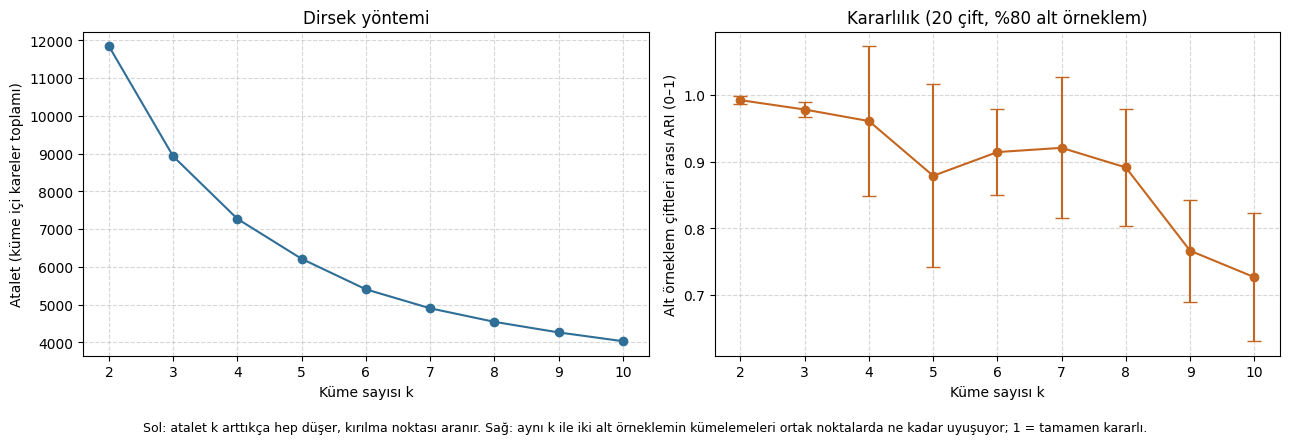

In [5]:
k_aralik = range(2, 11)
B = 20                       # kararlılık için alt örneklem çifti sayısı
oran = 0.8

ataletler, kar_ort, kar_std = [], [], []
for k in k_aralik:
    ataletler.append(KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z).inertia_)
    ari = []
    for b in range(B):
        r = np.random.default_rng(SEED + 1000 * k + b)
        i1 = r.choice(len(Z), size=int(oran * len(Z)), replace=False)
        i2 = r.choice(len(Z), size=int(oran * len(Z)), replace=False)
        ortak = np.intersect1d(i1, i2)
        m1 = KMeans(n_clusters=k, n_init=3, random_state=b).fit(Z[i1])
        m2 = KMeans(n_clusters=k, n_init=3, random_state=b + 500).fit(Z[i2])
        ari.append(adjusted_rand_score(m1.predict(Z[ortak]), m2.predict(Z[ortak])))
    kar_ort.append(np.mean(ari)); kar_std.append(np.std(ari))

k_tablo = pd.DataFrame({'atalet (inertia)': ataletler, 'kararlılık ARI ort.': kar_ort,
                        'kararlılık ARI std': kar_std}, index=pd.Index(list(k_aralik), name='k')).round(3)
display(k_tablo)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(list(k_aralik), ataletler, 'o-', color='#2F6E96')
ax[0].set_xlabel('Küme sayısı k'); ax[0].set_ylabel('Atalet (küme içi kareler toplamı)')
ax[0].set_title('Dirsek yöntemi'); ax[0].grid(True, ls='--', alpha=0.5)
ax[1].errorbar(list(k_aralik), kar_ort, yerr=kar_std, fmt='o-', capsize=5, color='#C4661F')
ax[1].set_xlabel('Küme sayısı k'); ax[1].set_ylabel('Alt örneklem çiftleri arası ARI (0–1)')
ax[1].set_title(f'Kararlılık ({B} çift, %{int(oran*100)} alt örneklem)'); ax[1].grid(True, ls='--', alpha=0.5)
fig.text(0.5, -0.04, 'Sol: atalet k arttıkça hep düşer, kırılma noktası aranır. Sağ: aynı k ile iki alt örneklemin '
         'kümelemeleri ortak noktalarda ne kadar uyuşuyor; 1 = tamamen kararlı.', ha='center', fontsize=9)
plt.tight_layout(); plt.show()

In [6]:
# k seçimi kuralı: k = 2 neredeyse her veride "iki yarıya bölme" olarak kararlıdır ve bu veride sıcak / soğuk
# mevsim ayrımına karşılık gelir; bu yüzden k ≥ 3 arasından, hem ortalaması yüksek hem dağılımı dar olan
# (ortalama − std en büyük) k seçiliyor.
aday = k_tablo.loc[k_tablo.index >= 3]
puan = aday['kararlılık ARI ort.'] - aday['kararlılık ARI std']
K = int(puan.idxmax())
print("Kararlılık puanı (ortalama − std), k ≥ 3:", puan.round(3).to_dict())
print(f"Seçilen k = {K}")

Kararlılık puanı (ortalama − std), k ≥ 3: {3: 0.967, 4: 0.849, 5: 0.742, 6: 0.85, 7: 0.815, 8: 0.803, 9: 0.691, 10: 0.631}
Seçilen k = 3


**Yorum:** Dirsek yöntemi net bir kırılma vermiyor: atalet k = 2'den 5'e hızla, sonra yavaş düşüyor ve "dirsek" 3 ile 5 arasında bir yere yayılıyor. Kararlılık analizi daha açık konuşuyor. k = 2 (ARI 0,992) ve k = 3 (0,978 ± 0,011) neredeyse tamamen kararlı; k = 4'te ortalama hâlâ yüksek (0,961) ama std 0,112'ye çıkıyor, yani bazı alt örneklem çiftlerinde kümeleme farklı bölünüyor. k ≥ 5'te ortalama 0,88–0,92'ye iner ve dağılım genişler. Ben-Hur vd.'nin (2002) önerdiği gibi yalnızca ortalamaya değil dağılımın biçimine de baktık: "ortalama − std" ölçütü k = 3'te açık ara en yüksek (0,967; ardından k = 6 ile 0,850). k = 2'yi seçmedik, çünkü iki kümeye bölme neredeyse her veride kararlıdır ve burada yalnızca sıcak ve soğuk mevsimi ayırır. Seçilen **k = 3**. Neyi söyleyemeyiz: "doğru" k diye bir şey yok; kararlılık k = 6–8'de de yüksek ve daha ince bir hava tipolojisi de savunulabilir.

### 1.3 Yöntemlerin karşılaştırması: KMeans, Gauss karışımı ve DBSCAN (yoğunluk temelli)

,Yöntem,küme sayısı,gürültü %,silhouette (gürültü hariç)
0,KMeans (k=3),3,0.0,0.388
1,Gauss karışımı (k=3),3,0.0,0.220
2,"DBSCAN (eps=0.45, min_samples=8)",1,3.1,NaN


Yöntemler arası uyum (ARI, gürültü noktaları hariç):


,KMeans (k=3),Gauss karışımı (k=3),"DBSCAN (eps=0.45, min_samples=8)"
KMeans (k=3),1.000,0.367,0.0
Gauss karışımı (k=3),0.367,1.000,0.0
"DBSCAN (eps=0.45, min_samples=8)",0.000,0.000,1.0


DBSCAN eps taraması:


,eps yüzdeliği,eps,küme sayısı,gürültü %,en büyük küme %
0,50,0.304,35,28.8,65.9
1,70,0.355,16,12.8,85.0
2,80,0.389,5,7.6,91.9
3,90,0.449,1,3.1,96.9
4,95,0.511,1,1.2,98.8


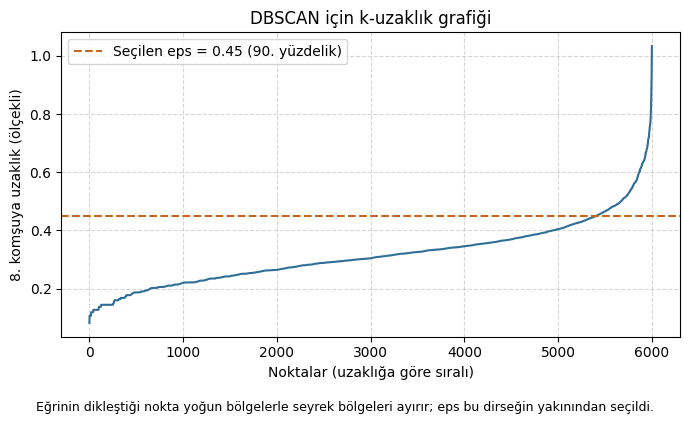

In [7]:
# DBSCAN için eps: min_samples'ıncı komşuya uzaklık eğrisinin (k-uzaklık grafiği) dirseği
min_samples = 2 * Z.shape[1]
k_uzak = np.sort(NearestNeighbors(n_neighbors=min_samples).fit(Z).kneighbors(Z)[0][:, -1])
eps = float(np.percentile(k_uzak, 90))

etiketler = {
    f'KMeans (k={K})': KMeans(n_clusters=K, n_init=10, random_state=SEED).fit_predict(Z),
    f'Gauss karışımı (k={K})': GaussianMixture(n_components=K, n_init=3, random_state=SEED).fit(Z).predict(Z),
    f'DBSCAN (eps={eps:.2f}, min_samples={min_samples})': DBSCAN(eps=eps, min_samples=min_samples).fit_predict(Z),
}

satir = []
for ad, e in etiketler.items():
    gurultu = (e == -1)
    kume_say = len(set(e[~gurultu]))
    sil = silhouette_score(Z[~gurultu], e[~gurultu]) if kume_say > 1 else np.nan
    satir.append({'Yöntem': ad, 'küme sayısı': kume_say, 'gürültü %': round(gurultu.mean() * 100, 1),
                  'silhouette (gürültü hariç)': round(sil, 3)})
display(pd.DataFrame(satir))

adlar = list(etiketler)
uyum = pd.DataFrame(index=adlar, columns=adlar, dtype=float)
for a in adlar:
    for b in adlar:
        ortak = (etiketler[a] != -1) & (etiketler[b] != -1)
        uyum.loc[a, b] = adjusted_rand_score(etiketler[a][ortak], etiketler[b][ortak])
print("Yöntemler arası uyum (ARI, gürültü noktaları hariç):")
display(uyum.round(3))

# DBSCAN eps'e duyarlıdır: farklı eps değerlerinde kaç küme ve ne kadar gürültü çıkıyor?
tarama = []
for yuzdelik in (50, 70, 80, 90, 95):
    e_ = float(np.percentile(k_uzak, yuzdelik))
    lab = DBSCAN(eps=e_, min_samples=min_samples).fit_predict(Z)
    boy = pd.Series(lab[lab != -1]).value_counts()
    tarama.append({'eps yüzdeliği': yuzdelik, 'eps': round(e_, 3), 'küme sayısı': int(boy.size),
                   'gürültü %': round((lab == -1).mean() * 100, 1),
                   'en büyük küme %': round(boy.max() / len(lab) * 100, 1) if boy.size else 0.0})
print("DBSCAN eps taraması:")
display(pd.DataFrame(tarama))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_uzak, color='#2F6E96')
ax.axhline(eps, color='#C4661F', ls='--', label=f'Seçilen eps = {eps:.2f} (90. yüzdelik)')
ax.set_xlabel('Noktalar (uzaklığa göre sıralı)'); ax.set_ylabel(f'{min_samples}. komşuya uzaklık (ölçekli)')
ax.set_title('DBSCAN için k-uzaklık grafiği'); ax.legend(); ax.grid(True, ls='--', alpha=0.5)
fig.text(0.5, -0.04, 'Eğrinin dikleştiği nokta yoğun bölgelerle seyrek bölgeleri ayırır; eps bu dirseğin yakınından seçildi.',
         ha='center', fontsize=9)
plt.tight_layout(); plt.show()

**Yorum:** KMeans (k = 3) silhouette 0,388 ile en düzgün ayrışmayı veriyor. Gauss karışımı aynı k ile daha düşük bir silhouette (0,220) ve KMeans ile yalnızca orta düzeyde bir uyum (ARI 0,367) veriyor; esnek eliptik bileşenleri sınırları farklı yerden çiziyor. DBSCAN ise belirgin kümeler **bulamıyor**: eps taraması bunu açıkça gösteriyor. Küçük eps'te (50. yüzdelik) 35 küçük küme ve %29 gürültü çıkıyor; eps biraz büyüyünce (90. yüzdelik) bütün veri tek bir dev kümede birleşiyor ve yalnızca %3 gürültü kalıyor. Aradaki hiçbir eps değerinde birkaç dengeli küme oluşmuyor. Bunun anlamı şu: hava verisi yoğunluk boşluklarıyla birbirinden ayrılmış kümelerden değil, **sürekli bir uzaydan** oluşuyor. KMeans bu sürekli uzayı anlamlı bölgelere ayırıyor; DBSCAN'in varsayımı (seyrek bölgelerle ayrılmış yoğun kümeler) bu veriye uymuyor. Bu yüzden profilleri KMeans ile çıkardık.

### 1.4 Küme profilleri ve "bu kümeler gerçek mi?"

,pay_yuzde,DEWP,TEMP,PRES,Iws_medyan,kar_saati,yagmur_saati,epizot_orani,pm25_medyan,baskin_yon,kis_payi_%,yaz_payi_%
kume,,,,,,,,,,,,
0,47.4,14.3,22.7,1007.9,4.9,0.0,0.3,55.1,84.0,SE,0.1,51.9
1,20.5,-12.5,3.7,1024.1,52.3,0.2,0.1,18.7,23.0,NW,44.7,0.0
2,32.2,-8.4,1.2,1024.3,2.7,0.1,0.1,58.3,93.0,cv,51.2,0.0


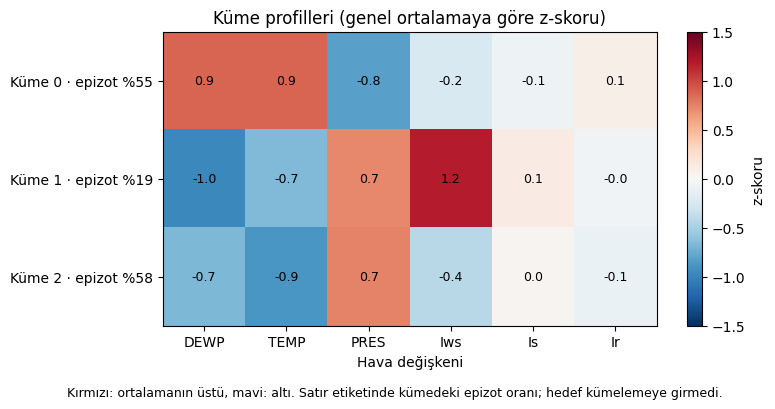

Silhouette · gerçek veri: 0.388 · sütunları karıştırılmış veri: 0.194
Seçilen k=3 için kararlılık ARI: 0.978 ± 0.011
Epizot oranı kümeler arasında: en düşük %19, en yüksek %58 (genel %49)


In [8]:
# KMeans örneklemde eğitildi; bütün geliştirme verisine atanıyor
km_final = Pipeline([('hat', clone(olcekli_hat)), ('km', KMeans(n_clusters=K, n_init=10, random_state=SEED))])
km_final.fit(H_ham)
dev['kume'] = km_final.predict(dev[kume_cols].values)

profil = dev.groupby('kume').agg(
    pay_yuzde=('kume', lambda s: len(s) / len(dev) * 100),
    DEWP=('DEWP', 'mean'), TEMP=('TEMP', 'mean'), PRES=('PRES', 'mean'),
    Iws_medyan=('Iws', 'median'), kar_saati=('Is', 'mean'), yagmur_saati=('Ir', 'mean'),
    epizot_orani=('kirlilik_epizodu', lambda s: s.mean() * 100),
    pm25_medyan=('pm2.5', 'median'))
profil['baskin_yon'] = dev.groupby('kume')['cbwd'].agg(lambda s: s.value_counts().index[0])
profil['kis_payi_%'] = dev.groupby('kume')['month'].agg(lambda s: s.isin([12, 1, 2]).mean() * 100)
profil['yaz_payi_%'] = dev.groupby('kume')['month'].agg(lambda s: s.isin([6, 7, 8]).mean() * 100)
display(profil.round(1))

# Profil ısı haritası: her değişkenin küme ortalaması, genel ortalamaya göre z-skoru
zp = (dev.groupby('kume')[hava_cols].mean() - dev[hava_cols].mean()) / dev[hava_cols].std()
fig, ax = plt.subplots(figsize=(8, 0.8 * K + 1.5))
im = ax.imshow(zp.values, cmap='RdBu_r', vmin=-1.5, vmax=1.5, aspect='auto')
ax.set_xticks(range(len(hava_cols))); ax.set_xticklabels(hava_cols)
ax.set_yticks(range(K)); ax.set_yticklabels([f'Küme {k} · epizot %{profil.loc[k, "epizot_orani"]:.0f}' for k in zp.index])
for i in range(K):
    for j in range(len(hava_cols)):
        ax.text(j, i, f'{zp.values[i, j]:.1f}', ha='center', va='center', fontsize=9)
ax.set_xlabel('Hava değişkeni'); ax.set_title('Küme profilleri (genel ortalamaya göre z-skoru)')
fig.colorbar(im, ax=ax, label='z-skoru')
fig.text(0.5, -0.03, 'Kırmızı: ortalamanın üstü, mavi: altı. Satır etiketinde kümedeki epizot oranı; hedef kümelemeye girmedi.',
         ha='center', fontsize=9)
plt.tight_layout(); plt.show()

# "Gerçek mi?" için ölçütler: kararlılık, yapısız veriyle karşılaştırma, epizot oranının kümelere göre ayrışması
Zk = sutun_karistir(Z)
sil_gercek = silhouette_score(Z, KMeans(n_clusters=K, n_init=10, random_state=SEED).fit_predict(Z))
sil_karisik = silhouette_score(Zk, KMeans(n_clusters=K, n_init=10, random_state=SEED).fit_predict(Zk))
print(f"Silhouette · gerçek veri: {sil_gercek:.3f} · sütunları karıştırılmış veri: {sil_karisik:.3f}")
print(f"Seçilen k={K} için kararlılık ARI: {k_tablo.loc[K, 'kararlılık ARI ort.']:.3f} ± {k_tablo.loc[K, 'kararlılık ARI std']:.3f}")
print(f"Epizot oranı kümeler arasında: en düşük %{profil['epizot_orani'].min():.0f}, en yüksek %{profil['epizot_orani'].max():.0f} "
      f"(genel %{dev['kirlilik_epizodu'].mean()*100:.0f})")

**Yorum:** Üç küme net birer hava tipine karşılık geliyor:

| Küme | Hava tipi | Pay | Ortalama | Epizot oranı | PM2.5 medyanı |
|---|---|---|---|---|---|
| 0 | **Sıcak ve nemli, güneydoğulu** (saatlerinin %52'si yazda) | %47 | 22,7 °C, çiy noktası 14,3 °C, 1008 hPa | **%55** | 84 µg/m³ |
| 1 | **Soğuk, kuru ve rüzgârlı, kuzeybatılı** (birikimli rüzgâr medyanı 52 m/s) | %21 | 3,7 °C, çiy noktası −12,5 °C, 1024 hPa | **%19** | 23 µg/m³ |
| 2 | **Soğuk ve durgun, değişken rüzgârlı** (saatlerinin %51'i kışta) | %32 | 1,2 °C, çiy noktası −8,4 °C, 1024 hPa | **%58** | 93 µg/m³ |

**Bu kümeler gerçek mi?** Beş ölçüt de "evet" yönünde: (1) seçilen k'da kararlılık 0,978 ± 0,011; (2) sütunları karıştırılmış veride silhouette 0,388'den 0,194'e düşüyor, Hopkins 0,854'ten 0,638'e; (3) KMeans ve Gauss karışımı kısmen uyumlu (ARI 0,37) bir yapı buluyor; (4) kümeler, kümelemeye hiç girmeyen mevsim ve rüzgâr yönüyle anlamlı biçimde örtüşüyor; (5) hedef kümelemede kullanılmadığı hâlde epizot oranı kümelere göre %19 ile %58 arasında ayrışıyor. En dikkat çekici bulgu iki soğuk kümenin farkı: sıcaklıkları neredeyse aynı (1–4 °C) ama kuzeybatı rüzgârının estiği küme %19, durgun küme %58 epizot oranına sahip. Yani kışın kirliliği belirleyen soğuk değil, **havanın hareketsizliği**. Bu, Proje 1'deki birliktelik kurallarıyla (durgun rüzgâr → epizot, kuzeybatı → temiz hava) aynı yönde.

**Neyi söyleyemeyiz:** DBSCAN'in gösterdiği gibi bu kümeler birbirinden boşluklarla ayrılmış "doğal türler" değil, sürekli bir hava uzayının kararlı bir bölümlenmesi. Küme sınırına yakın saatler iki tipe de benzeyebilir.

## Bölüm 2 · Aykırı gözlem
**Soru:** Hangi saatler olağandışı, bunlar veri hatası mı yoksa gerçek ama olağandışı kirlilik dönemleri mi, ve modeli nasıl etkiliyorlar?

**Kurulum:** Aykırılık skorları geliştirme verisinde, hava değişkenleri **ve PM2.5** ile hesaplanıyor; "olağandışı kirlilik dönemi" ancak PM2.5'i hava koşullarıyla birlikte görerek bulunabilir. Ölçekleme ve log dönüşümü 1.1'deki gibi.

### 2.1 İki yöntemle aykırılık skoru: Isolation Forest ve LOF

İki skorun sıra korelasyonu (Spearman ρ): 0.357


,en aykırı dilim,ortak saat,Jaccard
0,%1 (334 saat),20,0.031
1,%2 (668 saat),48,0.037
2,%5 (1670 saat),283,0.093


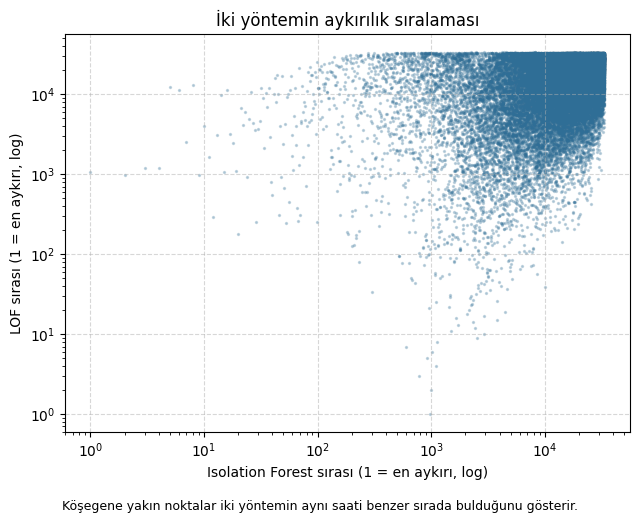

In [9]:
ay_cols = ['pm2.5'] + hava_cols
def log_donustur_ay(A):
    A = np.asarray(A, dtype=float).copy()
    for j, c in enumerate(ay_cols):
        if c in log_cols or c == 'pm2.5':
            A[:, j] = np.log1p(A[:, j])
    return A
ay_hat = Pipeline([('log', FunctionTransformer(log_donustur_ay)), ('scaler', StandardScaler())])
A = ay_hat.fit_transform(dev[ay_cols].values)

iforest = IsolationForest(n_estimators=300, contamination='auto', random_state=SEED, n_jobs=-1).fit(A)
dev['skor_if'] = -iforest.score_samples(A)                       # büyük = daha aykırı
lof = LocalOutlierFactor(n_neighbors=35, n_jobs=-1).fit(A)
dev['skor_lof'] = -lof.negative_outlier_factor_                  # büyük = daha aykırı

dev['sira_if'] = dev['skor_if'].rank(ascending=False).astype(int)
dev['sira_lof'] = dev['skor_lof'].rank(ascending=False).astype(int)

rho, p = spearmanr(dev['skor_if'], dev['skor_lof'])
uyum_satir = []
for yuzde in (1, 2, 5):
    n_ust = int(len(dev) * yuzde / 100)
    ust_if = set(dev.nsmallest(n_ust, 'sira_if').index)
    ust_lof = set(dev.nsmallest(n_ust, 'sira_lof').index)
    uyum_satir.append({'en aykırı dilim': f'%{yuzde} ({n_ust} saat)',
                       'ortak saat': len(ust_if & ust_lof),
                       'Jaccard': round(len(ust_if & ust_lof) / len(ust_if | ust_lof), 3)})
print(f"İki skorun sıra korelasyonu (Spearman ρ): {rho:.3f}")
display(pd.DataFrame(uyum_satir))

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(dev['sira_if'], dev['sira_lof'], s=2, alpha=0.25, color='#2F6E96')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Isolation Forest sırası (1 = en aykırı, log)'); ax.set_ylabel('LOF sırası (1 = en aykırı, log)')
ax.set_title('İki yöntemin aykırılık sıralaması'); ax.grid(True, ls='--', alpha=0.5)
fig.text(0.5, -0.03, 'Köşegene yakın noktalar iki yöntemin aynı saati benzer sırada bulduğunu gösterir.',
         ha='center', fontsize=9)
plt.tight_layout(); plt.show()

**Yorum:** İki yöntemin sıralamaları zayıf biçimde ilişkili (Spearman ρ = 0,357) ve en aykırı saatlerde neredeyse hiç örtüşmüyor: en aykırı %1'lik dilimde (334 saat) yalnızca 20 saat ortak (Jaccard 0,031), %5'lik dilimde 283 saat (Jaccard 0,093). Bu bir hata değil, iki farklı aykırılık tanımı. Isolation Forest *küresel* olarak "az ve farklı" olanı yalıtıyor (Liu vd., 2008): bütün veride nadir görülen değer bileşimleri, örneğin çok uzun süren yağmur ya da günlerce esen kuvvetli rüzgâr. LOF ise bir saati *kendi komşularıyla* karşılaştırıyor: genel olarak sıradan görünen ama yakın komşularına göre seyrek bir bölgede kalan saatleri buluyor. İki yöntemin ortak bulduğu saatler hem küresel olarak nadir hem de yerel olarak yalnız olanlar; 2.2'de bu yüzden iki sıranın ortalamasını kullandık.

### 2.2 En aykırı 20 kayıt: veri hatası mı, gerçek ama olağandışı mı?

In [10]:
# Bahar Bayramı (Çin Yeni Yılı) ilk günleri: havai fişekler kısa süreli PM2.5 sıçraması yaratır
bahar_bayrami = pd.to_datetime(['2010-02-14', '2011-02-03', '2012-01-23', '2013-02-10', '2014-01-31'])
def bayrama_yakin(t):
    return bool(np.any(np.abs((t.normalize() - bahar_bayrami).days) <= 1))

ilk20 = dev.assign(ort_sira=(dev['sira_if'] + dev['sira_lof']) / 2).nsmallest(20, 'ort_sira')
isaret = []
for _, r in ilk20.iterrows():
    n = []
    if r['DEWP'] > r['TEMP']: n.append('çiy noktası > sıcaklık (fiziksel olarak olanaksız)')
    if r['pm2.5'] >= 500: n.append('PM2.5 ≥ 500')
    if r['pm2.5'] <= 5: n.append('PM2.5 ≤ 5')
    if r['Iws'] >= 200: n.append('çok uzun süren rüzgâr')
    if r['Is'] >= 10 or r['Ir'] >= 10: n.append('uzun kar/yağmur')
    if bayrama_yakin(r['datetime']): n.append('Bahar Bayramı ±1 gün')
    isaret.append('; '.join(n))
ilk20 = ilk20.assign(isaretler=isaret)
display(ilk20[['datetime', 'pm2.5', 'DEWP', 'TEMP', 'PRES', 'cbwd', 'Iws', 'Is', 'Ir',
               'sira_if', 'sira_lof', 'isaretler']].reset_index(drop=True))

print("Kontrol · bütün geliştirme verisinde çiy noktası > sıcaklık olan saat:", int((dev['DEWP'] > dev['TEMP']).sum()))
print("Kontrol · ilk 20'nin aylara dağılımı:", ilk20['datetime'].dt.month.value_counts().sort_index().to_dict())

,datetime,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir,sira_if,sira_lof,isaretler
0,2010-09-21 03:00:00,1.0,13,14.0,1015.0,NE,48.73,0,9,20,181,PM2.5 ≤ 5
1,2011-06-08 04:00:00,7.0,16,19.0,996.0,NW,37.11,0,5,29,255,
2,2012-11-04 17:00:00,25.0,0,4.0,1013.0,NW,208.79,0,32,53,249,çok uzun süren rüzgâr; uzun kar/yağmur
3,2011-06-08 05:00:00,6.0,16,19.0,997.0,NW,41.13,0,6,12,291,
4,2013-01-02 23:00:00,27.0,-26,-11.0,1046.0,NW,341.10,0,0,233,80,çok uzun süren rüzgâr
5,2010-05-05 02:00:00,158.0,15,16.0,997.0,SE,57.66,0,6,67,258,
6,2013-01-03 04:00:00,20.0,-28,-12.0,1046.0,NW,384.01,0,0,203,128,çok uzun süren rüzgâr
7,2011-08-16 02:00:00,6.0,22,23.0,1003.0,NE,0.89,0,3,302,34,
8,2013-01-03 00:00:00,23.0,-27,-11.0,1046.0,NW,350.04,0,0,208,129,çok uzun süren rüzgâr
9,2010-09-18 07:00:00,5.0,12,13.0,1015.0,NE,5.37,0,35,46,305,PM2.5 ≤ 5; uzun kar/yağmur


Kontrol · bütün geliştirme verisinde çiy noktası > sıcaklık olan saat: 1
Kontrol · ilk 20'nin aylara dağılımı: {1: 9, 5: 1, 6: 3, 8: 1, 9: 2, 11: 4}


**Yorum:** En aykırı 20 saat dört olaya toplanıyor, ve çoğu **olağandışı kirlilik değil, olağandışı temiz hava**:

| Olay | Saatler | Ne var | Karar |
|---|---|---|---|
| 2–3 Ocak 2013 gecesi | 9 saat | Çiy noktası −28 °C, sıcaklık −12 °C, basınç 1046 hPa (verideki en yüksekler arasında), 330–394 m/s birikimli kuzeybatı rüzgârı, PM2.5 ≈ 20 | **Gerçek ama olağandışı:** çok güçlü bir soğuk hava dalgası. Bütün değişkenler fiziksel olarak tutarlı ve saatler ardışık. |
| 4 Kasım 2012 öğleden sonra | 4 saat | 29–32 saat kesintisiz yağış, 178–209 m/s kuzeybatı rüzgârı, PM2.5 23–27 | **Gerçek ama olağandışı:** uzun süren yağışlı bir fırtına; yağış ve rüzgâr kirleticiyi temizlemiş. |
| 8 Haziran 2011 gecesi | 3 saat | Düşük basınç (995–997 hPa), kuzeybatı rüzgârı, 4–6 saat yağmur, PM2.5 6–9 | **Gerçek ama olağandışı:** yaz fırtınası. |
| Tek tek saatler | 4 saat | 21 Eylül 2010: PM2.5 = 1 µg/m³ (9 saat yağmur, kuzeydoğu rüzgârı); 18 Eylül 2010: 35 saat yağmur, PM2.5 5; 3 Ocak 2010: 24 saat kesintisiz kar; 16 Ağustos 2011: durgun havada PM2.5 6 | Çoğu gerçek. **PM2.5 = 1 şüpheli:** ölçüm alt sınırına çok yakın; uzun yağmur açıklayabilir, ama doğrulanması gerekir. |
| 5 Mayıs 2010, 02:00 | 1 saat | 6 saat yağmur ve 58 m/s güneydoğu rüzgârına rağmen PM2.5 158 | **Olağandışı bileşim:** yağış ve rüzgâr genelde kirliliği düşürür. Güneydoğudan kirletici taşınması mümkün, ama tek saatlik bir ölçüm hatası da olabilir; ham kayıtlarla kontrol edilmeli. |

**Veri hatası:** İlk 20'de kesin bir veri hatası yok. Bütün geliştirme verisinde yalnızca **1 saatte çiy noktası sıcaklıktan yüksek**; bu fiziksel olarak olanaksız ve büyük olasılıkla bir ölçüm ya da yuvarlama hatası. Bahar Bayramı havai fişekleri ve PM2.5 ≥ 500 saatleri ilk 20'de yok.

**Bu ne anlama geliyor?** Epizotlar verinin yarısını oluşturduğu için yüksek PM2.5 tek başına "nadir" değil; aykırılık yöntemleri en çok aşırı *hava* olaylarını (soğuk dalga, uzun yağış) buluyor. "Olağandışı kirlilik dönemlerini" bulmak için PM2.5'i hava koşullarına göre beklenen değerle karşılaştırmak gerekir: örneğin bir regresyon modelinin artıklarında aykırılık aramak. 5 Mayıs 2010 saati bu türün tek örneği.

**Neyi söyleyemeyiz:** Kesin "hata" kararı için istasyonun ham ölçüm ve bakım kayıtları gerekir; elimizde yalnızca saatlik ortalamalar var.

### 2.3 Aykırı kayıtlar çıkarıldığında ya da işaretlendiğinde modelin değişimi

In [11]:
# Sızıntısız kurulum: her zamansal katta aykırılık modeli YALNIZCA o katın eğitim verisiyle eğitilir.
#  - Çıkar: eğitim katındaki en aykırı %1 ve %2 saat çıkarılır; doğrulama katına dokunulmaz.
#  - İşaretle: aykırılık skoru öznitelik olarak eklenir. PM2.5 tahmin anında bilinmediği için bu skor
#    yalnızca girdi özniteliklerinden (hava + zaman) hesaplanır.
def if_skoru(tr_matris, uygula_matris):
    sc = StandardScaler().fit(tr_matris)
    m = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1).fit(sc.transform(tr_matris))
    return -m.score_samples(sc.transform(uygula_matris))

Xd = X_dev.reset_index(drop=True); yd = y_dev.reset_index(drop=True)
dv = dev.reset_index(drop=True)
sonuc = {k: {'f1': [], 'bacc': []} for k in ['Seçilen model (değişiklik yok)', 'Eğitimden en aykırı %1 çıkarıldı',
                                               'Eğitimden en aykırı %2 çıkarıldı', 'Aykırılık skoru öznitelik olarak eklendi']}
for tr, va in tscv.split(Xd):
    s_tr = if_skoru(log_donustur_ay(dv.loc[tr, ay_cols].values), log_donustur_ay(dv.loc[tr, ay_cols].values))
    for ad, oran_cikar in [('Seçilen model (değişiklik yok)', 0), ('Eğitimden en aykırı %1 çıkarıldı', 1),
                           ('Eğitimden en aykırı %2 çıkarıldı', 2)]:
        tutulan = tr if oran_cikar == 0 else tr[s_tr < np.percentile(s_tr, 100 - oran_cikar)]
        m = clone(model_final).fit(Xd.loc[tutulan], yd.loc[tutulan])
        t = m.predict(Xd.loc[va])
        sonuc[ad]['f1'].append(f1_score(yd.loc[va], t)); sonuc[ad]['bacc'].append(balanced_accuracy_score(yd.loc[va], t))
    # İşaretle: skor girdi özniteliklerinden (modelin sayısal sütunları, cbwd hariç)
    g_tr, g_va = Xd.loc[tr, num_final].values, Xd.loc[va, num_final].values
    Xtr2 = Xd.loc[tr].assign(aykirilik=if_skoru(g_tr, g_tr))
    Xva2 = Xd.loc[va].assign(aykirilik=if_skoru(g_tr, g_va))
    pre2 = ColumnTransformer([('num', StandardScaler(), num_final + ['aykirilik']),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
    m2 = Pipeline([('preprocessor', pre2), ('classifier', clone(model_final.named_steps['classifier']))]).fit(Xtr2, yd.loc[tr])
    t2 = m2.predict(Xva2)
    ad = 'Aykırılık skoru öznitelik olarak eklendi'
    sonuc[ad]['f1'].append(f1_score(yd.loc[va], t2)); sonuc[ad]['bacc'].append(balanced_accuracy_score(yd.loc[va], t2))

etki = pd.DataFrame({ad: {'F1 (ortalama ± std)': f"{np.mean(v['f1']):.4f} ± {np.std(v['f1']):.4f}",
                          'Dengeli doğruluk (ortalama ± std)': f"{np.mean(v['bacc']):.4f} ± {np.std(v['bacc']):.4f}",
                          'F1 farkı (kat bazında ort.)': f"{np.mean(np.array(v['f1']) - np.array(sonuc['Seçilen model (değişiklik yok)']['f1'])):+.4f}"}
                     for ad, v in sonuc.items()}).T
display(etki)

,F1 (ortalama ± std),Dengeli doğruluk (ortalama ± std),F1 farkı (kat bazında ort.)
Seçilen model (değişiklik yok),0.7301 ± 0.0567,0.7292 ± 0.0276,+0.0000
Eğitimden en aykırı %1 çıkarıldı,0.7317 ± 0.0552,0.7304 ± 0.0272,+0.0016
Eğitimden en aykırı %2 çıkarıldı,0.7409 ± 0.0457,0.7365 ± 0.0252,+0.0108
Aykırılık skoru öznitelik olarak eklendi,0.7260 ± 0.0603,0.7246 ± 0.0311,-0.0041


**Yorum:**
**2.3 · Aykırıların modele etkisi.** Her katta aykırılık modeli yalnızca o katın eğitim verisiyle eğitildi. Eğitimden en aykırı %1'i çıkarmak F1'i neredeyse değiştirmedi (0,7301 → 0,7317, +0,002). %2'yi çıkarmak F1'i 0,7409'a, dengeli doğruluğu 0,729'dan 0,737'ye çıkardı (+0,011). Bu fark, katlar arası standart sapmanın (≈ 0,05) çok altında; yani anlamlı bir iyileşme olarak okunamaz. Standart sapmanın 0,057'den 0,046'ya düşmesi ise en aykırı saatlerin bazı katlarda öğrenmeyi bozduğunu düşündürüyor. Aykırılık skorunu öznitelik olarak eklemek F1'i biraz düşürdü (0,7260, −0,004). Sonuç: en aykırı saatler çoğunlukla gerçek aşırı hava olayları olduğu için onları silmek için güçlü bir gerekçe yok. Bu yüzden modelde değişiklik yapmıyoruz; %2 çıkarma, daha uzun bir veriyle yeniden sınanmaya değer bir seçenek olarak kalıyor.

## Bölüm 3 · Alt grup analizi
**Soru:** Model her koşulda aynı başarıda mı, yoksa belli mevsimlerde, saatlerde ya da rüzgâr yönlerinde zayıflıyor mu?

**Kurulum:** Veride kişilere ait bilgi yok, bu yüzden bir adillik analizi değil, **alt grup analizi** yapılıyor (Mehrabi vd., 2021). Alt gruplar: mevsim, günün saat dilimi ve rüzgâr yönü. İki kaynaktan tahmin kullanılıyor: (1) geliştirme verisinde 5 zamansal katın **kat dışı tahminleri** (her saat, onu görmemiş bir modelce tahmin edildi; kat bazında std verir), (2) **test dönemi** (2014): model geliştirme verisinin tamamıyla bir kez eğitilip test döneminde bir kez değerlendirildi. Test yalnızca raporlama için; hiçbir seçim ona göre yapılmadı.

### 3.1 Kat dışı ve test tahminleri

In [12]:
Xd = X_dev.reset_index(drop=True); yd = y_dev.reset_index(drop=True)
Xt = X_test.reset_index(drop=True); yt = y_test.reset_index(drop=True)
dv = df_clean.iloc[:split_idx].reset_index(drop=True)
ts = df_clean.iloc[split_idx:].reset_index(drop=True)

oof = pd.Series(np.nan, index=Xd.index); oof_kat = pd.Series(-1, index=Xd.index)
for k, (tr, va) in enumerate(tscv.split(Xd)):
    m = clone(model_final).fit(Xd.loc[tr], yd.loc[tr])
    oof.loc[va] = m.predict(Xd.loc[va]); oof_kat.loc[va] = k
model_test = clone(model_final).fit(Xd, yd)
pred_test = model_test.predict(Xt)

print(f"Seçilen model · geliştirme (kat dışı, 5 kat): F1 = {np.mean([f1_score(yd[oof_kat == k], oof[oof_kat == k]) for k in range(5)]):.4f}")
print(f"Seçilen model · TEST (2014, bir kez): F1 = {f1_score(yt, pred_test):.4f} · dengeli doğruluk = {balanced_accuracy_score(yt, pred_test):.4f} · doğruluk = {accuracy_score(yt, pred_test):.4f}")
tn, fp, fn, tp = confusion_matrix(yt, pred_test).ravel()
print(f"Test karışıklık matrisi: doğru negatif {tn} · yanlış pozitif {fp} · yanlış negatif {fn} · doğru pozitif {tp}")

def mevsim(ay):
    return np.select([np.isin(ay, [12, 1, 2]), np.isin(ay, [3, 4, 5]), np.isin(ay, [6, 7, 8])],
                     ['1 Kış', '2 İlkbahar', '3 Yaz'], '4 Sonbahar')
def saat_dilimi(s):
    return np.select([s < 6, s < 12, s < 18], ['1 Gece (00–05)', '2 Sabah (06–11)', '3 Öğleden sonra (12–17)'], '4 Akşam (18–23)')

for tablo, kaynak in ((dv, None), (ts, None)):
    tablo['mevsim'] = mevsim(tablo['month'].values)
    tablo['saat_dilimi'] = saat_dilimi(tablo['hour'].values)
dv['tahmin'] = oof.values; dv['kat'] = oof_kat.values
ts['tahmin'] = pred_test

Seçilen model · geliştirme (kat dışı, 5 kat): F1 = 0.7301
Seçilen model · TEST (2014, bir kez): F1 = 0.7527 · dengeli doğruluk = 0.7373 · doğruluk = 0.7323
Test karışıklık matrisi: doğru negatif 2713 · yanlış pozitif 1645 · yanlış negatif 591 · doğru pozitif 3403


### 3.2 Alt gruplara göre hata oranları

=== Mevsim · TEST dönemi (2014) ===


,n,epizot oranı,pozitif tahmin oranı,F1,duyarlılık (TPR),yanlış alarm (FPR),doğruluk,F1 · geliştirme kat dışı (ort ± std)
grup,,,,,,,,
1 Kış,1813,0.535,0.469,0.826,0.775,0.116,0.826,0.750 ± 0.077
2 İlkbahar,2202,0.509,0.574,0.778,0.827,0.311,0.759,0.732 ± 0.046
3 Yaz,2173,0.377,0.673,0.664,0.924,0.521,0.647,0.732 ± 0.061
4 Sonbahar,2164,0.500,0.680,0.756,0.892,0.468,0.712,0.699 ± 0.078


   TPR farkı (en yüksek − en düşük): 0.149 · FPR farkı (en yüksek − en düşük): 0.405 · F1 farkı (en yüksek − en düşük): 0.162

=== Günün saat dilimi · TEST dönemi (2014) ===


,n,epizot oranı,pozitif tahmin oranı,F1,duyarlılık (TPR),yanlış alarm (FPR),doğruluk,F1 · geliştirme kat dışı (ort ± std)
grup,,,,,,,,
1 Gece (00–05),2088,0.532,0.745,0.766,0.920,0.547,0.701,0.733 ± 0.049
2 Sabah (06–11),2089,0.502,0.582,0.773,0.834,0.328,0.753,0.754 ± 0.055
3 Öğleden sonra (12–17),2080,0.416,0.471,0.726,0.774,0.255,0.757,0.719 ± 0.078
4 Akşam (18–23),2095,0.463,0.619,0.739,0.864,0.408,0.718,0.710 ± 0.068


   TPR farkı (en yüksek − en düşük): 0.146 · FPR farkı (en yüksek − en düşük): 0.292 · F1 farkı (en yüksek − en düşük): 0.047

=== Rüzgâr yönü · TEST dönemi (2014) ===


,n,epizot oranı,pozitif tahmin oranı,F1,duyarlılık (TPR),yanlış alarm (FPR),doğruluk,F1 · geliştirme kat dışı (ort ± std)
grup,,,,,,,,
NE,960,0.427,0.506,0.754,0.824,0.269,0.771,0.718 ± 0.057
NW,2282,0.305,0.259,0.697,0.645,0.089,0.830,0.607 ± 0.100
SE,3124,0.547,0.738,0.756,0.888,0.557,0.686,0.748 ± 0.055
cv,1986,0.594,0.839,0.773,0.932,0.703,0.674,0.777 ± 0.030


   TPR farkı (en yüksek − en düşük): 0.288 · FPR farkı (en yüksek − en düşük): 0.614 · F1 farkı (en yüksek − en düşük): 0.075



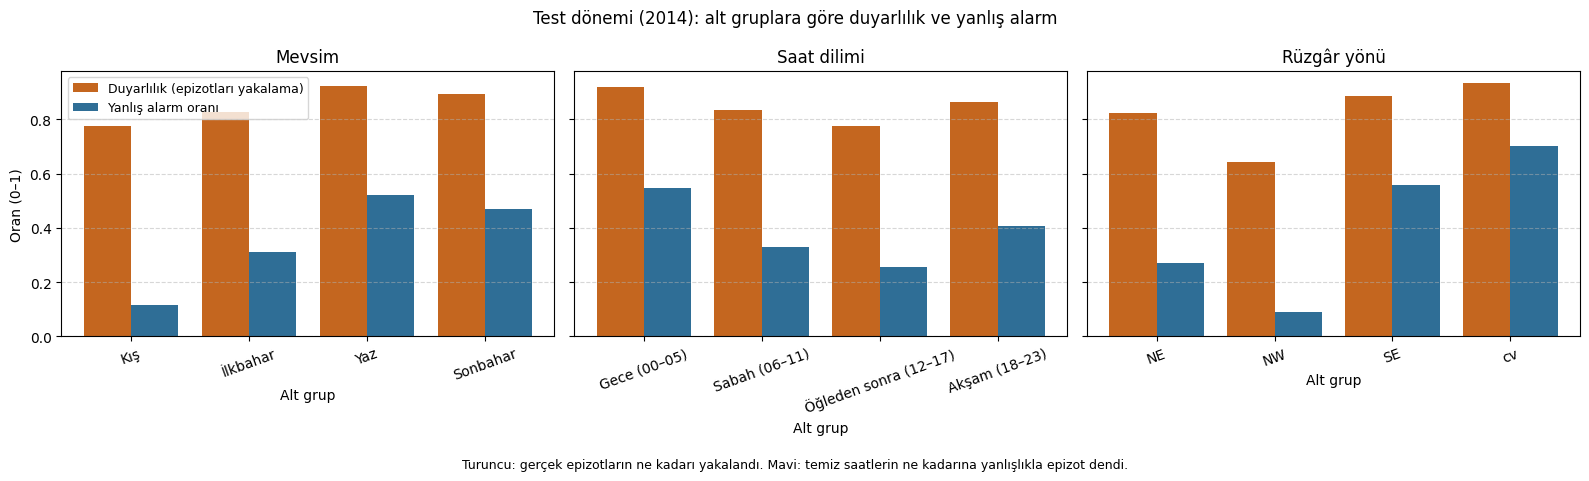

In [13]:
def grup_olcutleri(d, gercek='kirlilik_epizodu', tahmin='tahmin'):
    yv, pv = d[gercek].values, d[tahmin].values
    tp = ((yv == 1) & (pv == 1)).sum(); fn = ((yv == 1) & (pv == 0)).sum()
    fp = ((yv == 0) & (pv == 1)).sum(); tn = ((yv == 0) & (pv == 0)).sum()
    return {'n': len(d), 'epizot oranı': yv.mean(), 'pozitif tahmin oranı': pv.mean(),
            'F1': f1_score(yv, pv, zero_division=0),
            'duyarlılık (TPR)': tp / (tp + fn) if tp + fn else np.nan,
            'yanlış alarm (FPR)': fp / (fp + tn) if fp + tn else np.nan,
            'doğruluk': (tp + tn) / len(d)}

def alt_grup_tablosu(sutun):
    satir = []
    for g, d in ts.groupby(sutun):
        o = grup_olcutleri(d)
        f_kat = [f1_score(x['kirlilik_epizodu'], x['tahmin'], zero_division=0)
                 for _, x in dv[(dv[sutun] == g) & (dv['kat'] >= 0)].groupby('kat') if x['kirlilik_epizodu'].nunique() > 1]
        o['F1 · geliştirme kat dışı (ort ± std)'] = f"{np.mean(f_kat):.3f} ± {np.std(f_kat):.3f}" if f_kat else '–'
        o['grup'] = g; satir.append(o)
    t = pd.DataFrame(satir).set_index('grup')
    farklar = {'TPR farkı (en yüksek − en düşük)': t['duyarlılık (TPR)'].max() - t['duyarlılık (TPR)'].min(),
               'FPR farkı (en yüksek − en düşük)': t['yanlış alarm (FPR)'].max() - t['yanlış alarm (FPR)'].min(),
               'F1 farkı (en yüksek − en düşük)': t['F1'].max() - t['F1'].min()}
    return t, farklar

alt_sonuc = {}
for sutun, baslik in (('mevsim', 'Mevsim'), ('saat_dilimi', 'Günün saat dilimi'), ('cbwd', 'Rüzgâr yönü')):
    t, fr = alt_grup_tablosu(sutun)
    alt_sonuc[sutun] = (t, fr)
    print(f"=== {baslik} · TEST dönemi (2014) ===")
    display(t.round(3))
    print('   ' + ' · '.join(f'{k}: {v:.3f}' for k, v in fr.items()) + '\n')

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for a, (sutun, baslik) in zip(ax, (('mevsim', 'Mevsim'), ('saat_dilimi', 'Saat dilimi'), ('cbwd', 'Rüzgâr yönü'))):
    t = alt_sonuc[sutun][0]
    x = np.arange(len(t))
    a.bar(x - 0.2, t['duyarlılık (TPR)'], width=0.4, color='#C4661F', label='Duyarlılık (epizotları yakalama)')
    a.bar(x + 0.2, t['yanlış alarm (FPR)'], width=0.4, color='#2F6E96', label='Yanlış alarm oranı')
    a.set_xticks(x); a.set_xticklabels([str(i).split(' ', 1)[-1] for i in t.index], rotation=20)
    a.set_title(baslik); a.set_xlabel('Alt grup'); a.grid(axis='y', ls='--', alpha=0.5)
ax[0].set_ylabel('Oran (0–1)'); ax[0].legend(loc='upper left', fontsize=9)
fig.suptitle('Test dönemi (2014): alt gruplara göre duyarlılık ve yanlış alarm')
fig.text(0.5, -0.04, 'Turuncu: gerçek epizotların ne kadarı yakalandı. Mavi: temiz saatlerin ne kadarına yanlışlıkla epizot dendi.',
         ha='center', fontsize=9)
plt.tight_layout(); plt.show()

### 3.3 Hataların olası nedeni: eşiğe yakınlık ve dağılım kayması

Test dönemi · |PM2.5 − 75| dilimine göre hata oranı:


,saat,hata_orani,hataların payı %
esige_uzaklik,,,
0–10,893,0.457,18.247
10–25,1329,0.465,27.639
25–50,2059,0.368,33.855
50–100,2782,0.125,15.564
100+,1289,0.081,4.696


Mevsime göre epizot oranı · geliştirme ve test:


,geliştirme epizot oranı,test epizot oranı,test saat sayısı
mevsim,,,
1 Kış,0.465,0.535,1813
2 İlkbahar,0.451,0.509,2202
3 Yaz,0.542,0.377,2173
4 Sonbahar,0.489,0.500,2164


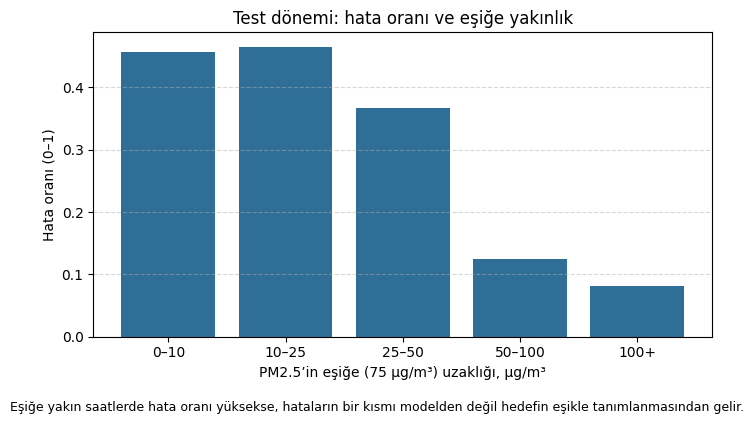

In [14]:
# 1) Eşiğe yakınlık: hedef, PM2.5'in 75 µg/m³ eşiğine göre tanımlanmış bir vekil. Eşiğe yakın saatlerde
#    küçük bir ölçüm farkı sınıfı değiştirir; hataların buralarda toplanması beklenir.
ts['esige_uzaklik'] = (ts['pm2.5'] - 75).abs()
ts['hata'] = (ts['tahmin'] != ts['kirlilik_epizodu']).astype(int)
uzak_dilim = pd.cut(ts['esige_uzaklik'], bins=[-0.1, 10, 25, 50, 100, 1000],
                    labels=['0–10', '10–25', '25–50', '50–100', '100+'])
esik_tablo = ts.groupby(uzak_dilim, observed=True).agg(saat=('hata', 'size'), hata_orani=('hata', 'mean'))
esik_tablo['hataların payı %'] = ts.groupby(uzak_dilim, observed=True)['hata'].sum() / ts['hata'].sum() * 100
print("Test dönemi · |PM2.5 − 75| dilimine göre hata oranı:")
display(esik_tablo.round(3))

# 2) Dağılım kayması: alt grupların epizot oranı geliştirme ile test arasında değişti mi?
kayma = pd.DataFrame({'geliştirme epizot oranı': dv.groupby('mevsim')['kirlilik_epizodu'].mean(),
                      'test epizot oranı': ts.groupby('mevsim')['kirlilik_epizodu'].mean(),
                      'test saat sayısı': ts.groupby('mevsim').size()})
print("Mevsime göre epizot oranı · geliştirme ve test:")
display(kayma.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(esik_tablo.index.astype(str), esik_tablo['hata_orani'], color='#2F6E96')
ax.set_xlabel('PM2.5’in eşiğe (75 µg/m³) uzaklığı, µg/m³'); ax.set_ylabel('Hata oranı (0–1)')
ax.set_title('Test dönemi: hata oranı ve eşiğe yakınlık'); ax.grid(axis='y', ls='--', alpha=0.5)
fig.text(0.5, -0.04, 'Eşiğe yakın saatlerde hata oranı yüksekse, hataların bir kısmı modelden değil hedefin eşikle tanımlanmasından gelir.',
         ha='center', fontsize=9)
plt.tight_layout(); plt.show()

**Yorum:**

**Genel tablo:** Seçilen model test döneminde (2014) F1 0,753 ve dengeli doğruluk 0,737 veriyor; geliştirme verisindeki 0,730 ile tutarlı. Ama hatalar dengesiz: 1.645 yanlış alarma karşılık yalnızca 591 kaçırılan epizot var. Model test döneminde fazla "epizot" diyor.

**Mevsim:** En büyük fark burada. Kışın model iyi (F1 0,826, yanlış alarm %12), yazın en zayıf (F1 0,664, yanlış alarm **%52**). Yazın model saatlerin %67'sine epizot diyor, ama gerçekte yalnızca %38'i epizot. Nedeni **dağılım kayması**: yaz epizot oranı geliştirme verisinde %54 iken 2014 yazında %38'e düştü. Model eski yazları öğrendi; 2014 yazı daha temizdi. Hava koşulları benzer görünse de kirlilik düzeyi değişmiş. Liang vd. (2015), 2014'teki APEC zirvesi öncesi alınan önlemlerin kirliliği düşürdüğünü gösteriyor; yaz düşüşünün de benzer bir emisyon değişikliğinden gelip gelmediğini veriyle sınayamayız, çünkü veride emisyon bilgisi yok.

**Rüzgâr yönü:** Kuzeybatı rüzgârında model epizotların yalnızca %65'ini yakalıyor (en düşük duyarlılık); geliştirme verisinde bu grupta F1 0,607 ± 0,100 ile en zayıf ve en kararsız. Kuzeybatı rüzgârında epizot nadir (%31) ve model bu koşulda epizot beklemiyor. Durgun rüzgârda (cv) tersi oluyor: duyarlılık %93 ama yanlış alarm **%70**. Model durgun havayı neredeyse otomatik olarak epizot sayıyor. İki uç arasında duyarlılık farkı 0,29, yanlış alarm farkı 0,61; eşitlenmiş olasılıklar açısından en büyük dengesizlik rüzgâr yönünde.

**Saat dilimi:** F1 farkı küçük (0,047) ama gece yanlış alarm %55, öğleden sonra %26. Muhtemel bir neden: gece rüzgâr zayıflar ve hava durgunlaşır; model durgun havayı epizotla eşleştirdiği için (rüzgâr yönü bulgusu) gece saatlerinde fazla alarm veriyor.

**Neyi söyleyemeyiz:** Test sonuçları tek bir yıla (2014) ait. Alt gruplardaki farkların bir kısmı o yılın özel koşullarından gelebilir; geliştirme verisindeki kat bazındaki std'ler bu belirsizliğin büyüklüğünü gösteriyor.

**Eşiğe yakınlık (3.3):**
**Eşiğe yakınlık.** Test döneminde PM2.5 değeri 75 µg/m³ eşiğine 10 birimden yakın olan saatlerde hata oranı %45,7, 10–25 aralığında %46,5. Bu oran yazı tura atmaya yakın. Eşikten 100 birimden fazla uzak saatlerde hata oranı %8'e iniyor. Hataların %46'sı eşiğin ±25 birimi içinde; 25–50 aralığı da eklenince bu pay %80'e çıkıyor. Yani modelin hatalarının çoğu "yanlış hava tipini tanımak"tan değil, eşiğin hemen üstündeki ve altındaki saatleri ayırmanın doğal zorluğundan geliyor. Bu sınır bölgesindeki hatalar ölçüm gürültüsüne de duyarlı. Yazın yanlış alarm oranının yüksek olması da bununla tutarlı: 2014 yazında epizot oranı %54'ten %38'e düştü ve birçok yaz saati eşiğin hemen altında kaldı.

## Ek paket 1 · Kümeler ve sınıflandırma
**Kurulum:** Kümeler Bölüm 1'deki gibi dört hava değişkeniyle (çiy noktası, sıcaklık, basınç, log birikimli rüzgâr) ve aynı k ile kuruluyor. Küme bilgisinin modele eklendiği ve kümeye göre ayrı model kurulan deneylerde **kümeleme hattın içinde**: her zamansal katta yalnızca o katın eğitim verisiyle öğreniliyor, doğrulama katına yalnızca atanıyor.

### EP1.1 Modelin kümelere göre hataları

In [15]:
dv['kume'] = km_final.predict(dv[kume_cols].values)
ts['kume'] = km_final.predict(ts[kume_cols].values)
kume_satir = []
for g, d in ts.groupby('kume'):
    o = grup_olcutleri(d)
    f_kat = [f1_score(x['kirlilik_epizodu'], x['tahmin'], zero_division=0)
             for _, x in dv[(dv['kume'] == g) & (dv['kat'] >= 0)].groupby('kat') if x['kirlilik_epizodu'].nunique() > 1]
    o['F1 · geliştirme kat dışı (ort ± std)'] = f"{np.mean(f_kat):.3f} ± {np.std(f_kat):.3f}" if f_kat else '–'
    o['kume'] = f"Küme {g} · {profil.loc[g, 'baskin_yon']}, ort. {profil.loc[g, 'TEMP']:.0f} °C"
    kume_satir.append(o)
kume_hata = pd.DataFrame(kume_satir).set_index('kume')
print("Test dönemi (2014) · kümelere göre:")
display(kume_hata.round(3))

Test dönemi (2014) · kümelere göre:


,n,epizot oranı,pozitif tahmin oranı,F1,duyarlılık (TPR),yanlış alarm (FPR),doğruluk,F1 · geliştirme kat dışı (ort ± std)
kume,,,,,,,,
"Küme 0 · SE, ort. 23 °C",4473,0.490,0.688,0.724,0.871,0.512,0.675,0.735 ± 0.045
"Küme 1 · NW, ort. 4 °C",1341,0.209,0.175,0.660,0.607,0.061,0.870,0.463 ± 0.128
"Küme 2 · cv, ort. 1 °C",2538,0.600,0.684,0.813,0.869,0.404,0.760,0.756 ± 0.075


### EP1.2 Küme bilgisinin öznitelik olarak eklenmesi ve kümelere göre ayrı modeller

,F1 (ortalama ± std),Dengeli doğruluk (ortalama ± std),F1 farkı (kat bazında ort.)
Tek model (seçilen model),0.7301 ± 0.0567,0.7292 ± 0.0276,+0.0000
Tek model + küme özniteliği,0.7420 ± 0.0370,0.7347 ± 0.0288,+0.0119
Kümeye göre ayrı modeller (3 model),0.7314 ± 0.0549,0.7355 ± 0.0272,+0.0013


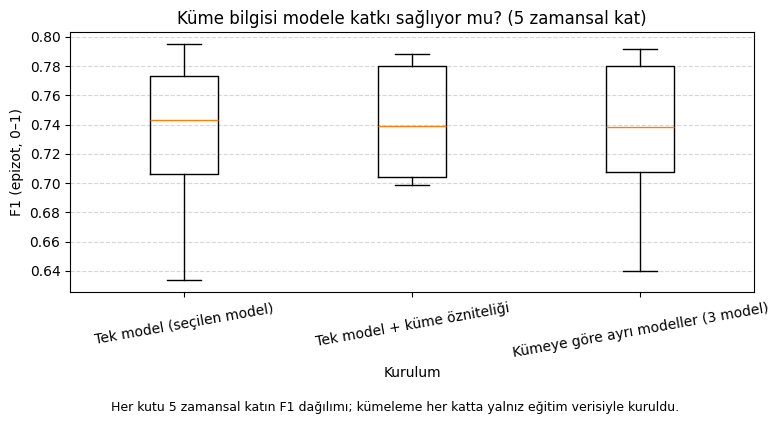

In [16]:
class KumeOzniteligi(BaseEstimator, TransformerMixin):
    """Her katta yalnız eğitim verisiyle KMeans kurar; küme numarasını yeni bir kategorik sütun olarak ekler."""
    def __init__(self, k=3, seed=42):
        self.k = k; self.seed = seed
    def _matris(self, X):
        return log_donustur(X[kume_cols].values)
    def fit(self, X, y=None):
        A = self._matris(X)
        self.sc_ = StandardScaler().fit(A)
        self.km_ = KMeans(n_clusters=self.k, n_init=10, random_state=self.seed).fit(self.sc_.transform(A))
        return self
    def ata(self, X):
        return self.km_.predict(self.sc_.transform(self._matris(X)))
    def transform(self, X):
        return X.assign(kume=self.ata(X).astype(str))

class KumeBasinaModel(BaseEstimator, ClassifierMixin):
    """Her katta kümeleri yalnız eğitim verisiyle kurar ve her kümeye ayrı bir model eğitir."""
    def __init__(self, temel=None, k=3, seed=42):
        self.temel = temel; self.k = k; self.seed = seed
    def fit(self, X, y):
        self.kume_ = KumeOzniteligi(self.k, self.seed).fit(X)
        etiket = self.kume_.ata(X); y = np.asarray(y)
        self.classes_ = np.unique(y); self.modeller_ = {}
        for c in range(self.k):
            secim = etiket == c
            if len(np.unique(y[secim])) < 2:      # tek sınıflı küme: sabit tahmin
                self.modeller_[c] = int(y[secim][0]) if secim.any() else int(np.round(y.mean()))
            else:
                self.modeller_[c] = clone(self.temel).fit(X[secim], y[secim])
        return self
    def predict(self, X):
        etiket = self.kume_.ata(X); p = np.zeros(len(X), dtype=int)
        for c, m in self.modeller_.items():
            secim = etiket == c
            if secim.any():
                p[secim] = m if isinstance(m, int) else m.predict(X[secim])
        return p

clf_final = model_final.named_steps['classifier']
pre_kume = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_final),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols + ['kume'])])
deneyler = {
    'Tek model (seçilen model)': clone(model_final),
    'Tek model + küme özniteliği': Pipeline([('kume', KumeOzniteligi(K, SEED)), ('preprocessor', pre_kume),
                                             ('classifier', clone(clf_final))]),
    f'Kümeye göre ayrı modeller ({K} model)': KumeBasinaModel(temel=clone(model_final), k=K, seed=SEED),
}
ep1 = {}
for ad, m in deneyler.items():
    r = cross_validate(m, X_dev, y_dev, cv=tscv, scoring=['f1', 'balanced_accuracy'], n_jobs=-1)
    ep1[ad] = r
ep1_tablo = pd.DataFrame({ad: {'F1 (ortalama ± std)': f"{r['test_f1'].mean():.4f} ± {r['test_f1'].std():.4f}",
                               'Dengeli doğruluk (ortalama ± std)': f"{r['test_balanced_accuracy'].mean():.4f} ± {r['test_balanced_accuracy'].std():.4f}",
                               'F1 farkı (kat bazında ort.)': f"{np.mean(r['test_f1'] - ep1['Tek model (seçilen model)']['test_f1']):+.4f}"}
                          for ad, r in ep1.items()}).T
display(ep1_tablo)

fig, ax = plt.subplots(figsize=(8, 4))
adlar_ep1 = list(ep1)
ax.boxplot([ep1[a]['test_f1'] for a in adlar_ep1])
ax.set_xticks(range(1, len(adlar_ep1) + 1)); ax.set_xticklabels(adlar_ep1, rotation=10)
ax.set_xlabel('Kurulum'); ax.set_ylabel('F1 (epizot, 0–1)')
ax.set_title('Küme bilgisi modele katkı sağlıyor mu? (5 zamansal kat)'); ax.grid(axis='y', ls='--', alpha=0.5)
fig.text(0.5, -0.04, 'Her kutu 5 zamansal katın F1 dağılımı; kümeleme her katta yalnız eğitim verisiyle kuruldu.',
         ha='center', fontsize=9)
plt.tight_layout(); plt.show()

**Yorum:**

**Kümelere göre hata:** Model en çok **soğuk-kuru kuzeybatı kümesinde** zorlanıyor. Bu kümede geliştirme verisindeki F1 0,463 ± 0,128, test döneminde 0,660; duyarlılık yalnızca %61. Bu kümede epizot nadir (%21), ve model buradaki birkaç epizodu "temiz hava" ile karıştırıyor. Bölüm 3'teki kuzeybatı rüzgârı bulgusunun aynısı; kümeler rüzgâr yönüyle örtüştüğü için şaşırtıcı değil. Sıcak-nemli kümede (küme 0) sorun yanlış alarm (%51); bu da yaz kaymasıyla aynı. En iyi çalıştığı yer durgun kış kümesi (test F1 0,813).

**Küme bilgisi öznitelik olarak:** Küme numarası eklenince F1 0,730'dan 0,742'ye çıktı (kat bazında ortalama +0,012) ve katlar arası std 0,057'den 0,037'ye düştü. Fark std'nin içinde, yani anlamlı bir iyileşme diyemeyiz. Ama std'nin düşmesi, küme bilgisinin özellikle zayıf katlarda modeli dengelediğini düşündürüyor. Kümeler zaten modelin gördüğü değişkenlerden türetildiği için büyük bir kazanç beklenmiyordu; kazanç, hava tipini tek bir değişkende özetlemesinden geliyor.

**Kümeye göre ayrı modeller:** Üç ayrı model tek modelle aynı başarıda (F1 0,731, fark +0,001). Her model daha az veriyle eğitiliyor; özellikle %21'lik kuzeybatı kümesinin modeli az sayıda epizotla öğreniyor. Rastgele orman zaten kendi içinde hava tiplerine göre bölmeler yapabildiği için ayrı modellerin bir avantajı yok.

**Sonuç:** Küme bilgisi modele küçük ve istikrarlı bir katkı sağlıyor, ama farkı anlamlı saymak için yeterli değil. Asıl değeri tanısal: modelin hangi hava tipinde zayıf olduğunu (kuzeybatı: kaçırma, yaz: yanlış alarm) açıkça gösteriyor. Kurulum sızıntısız: kümeleme her katta yalnızca o katın eğitim verisiyle yapıldı.

## Tez ve araştırma yönleri
Tez öncülü: *İstanbul gibi yerel bir şehrin açık hava kalitesi verisiyle kirlilik epizotlarını erken tespit eden uygulamalı bir tez.*

**(1) Araştırma sorusu:** İstanbul'da Ulusal Hava Kalitesi İzleme Ağı'nın saatlik PM2.5 ölçümleri ve meteoroloji verisiyle bir kirlilik epizodu 6–24 saat önceden, zamansal sızıntı olmadan hangi başarıyla tespit edilebilir, ve bu başarı istasyonlar ile mevsimler arasında nasıl değişir?

**(2) Projeden çıkan gerekçe:** (a) Pekin verisinde aynı saatin havasıyla yapılan *anlık* tespit F1 ≈ 0,73–0,75 veriyor; meteoroloji güçlü bir sinyal taşıyor (Bölüm 1: kuzeybatı rüzgârlı soğuk havada epizot oranı %19, durgun soğuk havada %58). Ama gerçek bir uyarı *önceden* verilmeli; bu projede bunu hiç sınamadık. (b) Değerlendirme protokolü sonucu belirliyor: Proje 1'de veriyi karıştırmak doğruluğu 16 puan, OOB hatası 6 puan iyimser gösterdi. Erken tespitte, tahmin ufku kadar boşluklu zamansal bölme şart. (c) Bölüm 3'te 2014 yazında epizot oranı %54'ten %38'e düştü ve model yanlış alarma kaydı; emisyon değişiklikleri modelin zamanla bozulmasına yol açıyor (Liang vd., 2015, APEC önlemlerinin etkisini gösteriyor). Bu yüzden modelin güncellenmesi tezin parçası olmalı. (d) Pekin verisinde hedef tek bir istasyondu; İstanbul'da şehrin farklı bölgelerinde çok sayıda istasyon var, bu da "tek istasyon vekili" sorununu çözmeye izin veriyor.

**(3) Gerekenler:** *Veri:* Ulusal Hava Kalitesi İzleme Ağı'nın istasyon bazında saatlik PM2.5 ve PM10 ölçümleri (Bakanlık bunları havaizleme.gov.tr'de saatlik yayımlıyor), saatlik meteoroloji (Meteoroloji Genel Müdürlüğü ya da ERA5 yeniden analizi; gerçek kullanımda gözlem değil meteoroloji *tahmini*), takvim (resmî tatiller, bayramlar). Türk mevzuatında günlük PM2.5 sınır değeri tanımlı değil; epizot eşiği Dünya Sağlık Örgütü'nün günlük kılavuz değeri gibi gerekçeli bir değere göre konmalı. *Yöntem:* gecikmeli öznitelikler (t−1 … t−24 PM2.5), her ufuk için ayrı model, olasılık kalibrasyonu, Proje 2'deki gibi hava tipi kümeleri. *Protokol:* genişleyen pencereli zamansal CV ve en az tahmin ufku kadar boşluk; dokunulmayan son yıl; istasyon dışarıda bırakılarak (leave-station-out) değerlendirme; mevsime, istasyon tipine (trafik, sanayi, kentsel) ve rüzgâr rejimine göre alt grup analizi.

**(4) Fizibilite ve riskler:** Veri herkese açık ve saatlik; bir yüksek lisans tezi süresinde toplanabilir. Riskler: istasyonlardaki uzun eksiklikler (Proje 1'de Pekin'de 155 saatlik boşluklar gördük), istasyonların açılıp kapanması ve ölçüm yöntemi değişiklikleri; meteoroloji tahmini hatasının erken uyarıya eklenmesi; politika ve emisyon değişikliklerinden kaynaklanan kayma; yanlış alarm ile kaçırılan epizot arasındaki maliyet dengesinin karar vericiyle birlikte tanımlanması gereği.

## Model kartı
| | |
|---|---|
| **Model** | Rastgele orman (`RandomForestClassifier`, 100 ağaç, `max_depth = 10`, `random_state = 42`), ön işlemeyle tek bir `Pipeline` içinde (sayısal: medyanla doldurma + standartlaştırma; rüzgâr yönü: bire-bir kodlama). |
| **Amaç** | Pekin'de bir saatin, aynı saatin hava koşullarına göre kirlilik epizodu (PM2.5 > 75 µg/m³) olup olmadığını *anlık* olarak tespit etmek. Bir araştırma ve ders projesidir. |
| **Girdiler** | Ay, saat, çiy noktası, sıcaklık, basınç, rüzgâr yönü, birikimli rüzgâr hızı, birikimli kar ve yağmur saatleri. (`year` ve `day` 1.2'de çıkarıldı.) |
| **Eğitim verisi** | UCI Beijing PM2.5 (Liang vd., 2015), 2 Ocak 2010 – 14 Ocak 2014, 33.405 saat. PM2.5: ABD Büyükelçiliği istasyonu; meteoroloji: Pekin Başkent Havalimanı. |
| **Değerlendirme** | Geliştirmede `TimeSeriesSplit(5, gap=24)`: F1 0,730 ± 0,057, dengeli doğruluk 0,729 ± 0,028. Dokunulmayan test (14 Ocak – 31 Aralık 2014, 8.352 saat, bir kez): **F1 0,753, dengeli doğruluk 0,737, doğruluk 0,732**; 1.645 yanlış alarm, 591 kaçırılan epizot. |
| **Alt gruplar (test)** | En iyi: kış (F1 0,83), durgun soğuk hava kümesi (0,81). En zayıf: yaz (F1 0,66, yanlış alarm %52), kuzeybatı rüzgârı (duyarlılık %65), kuzeybatılı soğuk-kuru hava kümesi (F1 0,66). Durgun rüzgârda yanlış alarm %70. |
| **Sınırlılıklar** | Hedef bir vekil: tek istasyon, saatlik değere uygulanmış 24 saatlik bir eşik. Zamanla kayma var (2014 yazında epizot oranı %54'ten %38'e düştü); model yeni dönemde fazla epizot diyor. Emisyon bilgisi yok; model yalnızca meteorolojiyi görüyor. Tek bir şehir ve 2010–2014 dönemi. |
| **Uygun olmayan kullanımlar** | Erken uyarı (model geleceği tahmin etmez, aynı saatin havasını kullanır); başka bir şehre ya da döneme yeniden eğitim ve doğrulama yapılmadan aktarılması; tek başına sağlık ya da politika kararı dayanağı olarak kullanılması; olasılık gibi yorumlanması (çıktı kalibre edilmedi). |

## Sonuç ve sınırlılıklar
- **Hava tipleri gerçek ve kirlilikle güçlü biçimde ilişkili (Bölüm 1).** Dört hava değişkeni kararlı üç tipe ayrılıyor; hedef kümelemeye girmediği hâlde epizot oranı tipler arasında %19 ile %58 arasında değişiyor. Kışın kirliliği soğuk değil, durgunluk belirliyor. Ama tipler boşluklarla ayrılmış değil, sürekli bir uzayın bölümlenmesi (DBSCAN küme bulamadı).
- **Aykırı gözlemler (Bölüm 2):** Isolation Forest ve LOF farklı aykırılık türleri buluyor (ρ = 0,36). En aykırı saatler çoğunlukla aşırı *hava* olayları (Ocak 2013 soğuk dalgası, uzun yağışlı fırtınalar) ve bunlarda kirlilik düşük; gerçek ama olağandışı kayıtlar. Kesin veri hatası bulunmadı; bir saatte çiy noktası sıcaklıktan yüksek. Aykırıları eğitimden çıkarmak F1'i en fazla +0,011 artırdı (%2 çıkarıldığında); bu fark katlar arası sapmanın içinde kaldığı için model değiştirilmedi.
- **Model her koşulda eşit değil (Bölüm 3, Ek paket 1).** Kuzeybatı rüzgârında epizotları kaçırıyor, yazın ve durgun havada fazla yanlış alarm veriyor. Yaz sorununun ana nedeni 2014'teki dağılım kayması. Küme bilgisi modele küçük bir katkı sağlıyor (F1 +0,012), ama bu katkı std'nin içinde.
- **Proje 1'den düzeltme:** `year` ve `day` çıkarıldı; başarı korundu, model sadeleşti.
- **Genel sınırlılıklar:** Tek şehir, tek istasyon, tek test yılı. Bütün sonuçlar anlık tespit için; erken uyarı ayrı bir soru (Tez ve araştırma yönleri). Weka kontrolü Proje 1'de yapıldı; Proje 2'deki yöntemler için bağımsız bir araç kontrolü yapılmadı.

## Varsayım defteri
- **Kümeleme değişkenleri:** Çiy noktası, sıcaklık, basınç ve log birikimli rüzgâr. Kar ve yağmur saatleri saatlerin %96–99'unda sıfır olduğu için dışarıda bırakıldı; zaman sütunları mevsimselliği doğrudan kümelemeye sokmamak için dışarıda bırakıldı.
- **Ölçekleme:** Standartlaştırma. Birimler farklı ve hiçbir değişkene öncelik vermek için gerekçe yok (1.1).
- **Örneklem:** Hopkins, kararlılık ve DBSCAN için geliştirme verisinden 6.000 saatlik rastgele örneklem; zaman sırası kümelemede önemli değil. Profiller bütün geliştirme verisiyle.
- **k seçimi:** k ≥ 3 arasında kararlılık ARI'sinin ortalama − std değeri en yüksek k (Ben-Hur vd., 2002). k = 2 önemsiz biçimde kararlı olduğu için dışarıda.
- **DBSCAN:** `min_samples` = 2 × boyut = 8; eps k-uzaklık grafiğinin 90. yüzdeliği, ayrıca 50–95. yüzdelikler tarandı.
- **Aykırılık değişkenleri:** Hava değişkenleri ve PM2.5 (olağandışı kirlilik dönemlerini bulmak için). Modele öznitelik olarak eklenen skor ise yalnızca girdilerden, çünkü tahmin anında PM2.5 bilinmez.
- **Aykırı çıkarma oranı:** %1 ve %2; aykırılık modeli her katta yalnız eğitim verisiyle.
- **Model seçimi:** Proje 1 ile aynı kural, geliştirme verisinde zamansal CV F1. Test yalnızca raporlama için bir kez.
- **Alt gruplar:** Mevsim (Aralık–Şubat kış), dört saat dilimi, rüzgâr yönü. Veride kişi bilgisi yok; adillik değil alt grup analizi (Mehrabi vd., 2021).
- **Küme özniteliği:** Kümeleme her katta yalnız eğitim verisiyle (`KumeOzniteligi`), aynı k = 3.

## Katkı beyanı

| Üye | Numara | Sorumlu olduğu bölüm | Sunumda anlattığı |
|---|---|---|---|
| Süleyman Balsak | 254312022 | Proje 1'den devralınanlar ve düzeltmeler · Bölüm 1: kümeleme eğilimi (Hopkins), ölçeklemenin etkisi, k seçimi (dirsek ve kararlılık), KMeans / Gauss karışımı / DBSCAN, küme profilleri | Bölüm 1 · Kümeleme |
| Seda Erten | 254312008 | Bölüm 2: Isolation Forest ve LOF, iki sıralamanın uyumu, en aykırı 20 kayıt, aykırıların modele etkisi | Bölüm 2 · Aykırı gözlem |
| İlkin Urcan | 244329078 | Bölüm 3: mevsime, saat dilimine ve rüzgâr yönüne göre alt grup analizi; hataların nedenleri; model kartı | Bölüm 3 · Alt grup analizi |
| Aslıhan Semiz Varlı | 254329024 | Ek paket 1: kümelere göre hata analizi, küme bilgisinin sızıntısız öznitelik olarak eklenmesi, kümeye göre ayrı modeller · tez ve araştırma yönleri | Ek paket 1 · Kümeler ve sınıflandırma |

## Yapay zekâ beyanı
Bu projede Claude (Anthropic), grubun yönlendirmesiyle kodlama ve yazım asistanı olarak kullanılmıştır. Kodun yazılması ve optimize edilmesinde, sızıntı kontrolünde ve yorum metinlerinin ilk taslaklarında Claude'dan destek alınmıştır.

Konu ve modelin belirlenmesi, defterin Colab'da çalıştırılması, çıktıların kontrolü, metinlerin düzeltilmesi ile sunum ve video grup tarafından yapılmıştır. Defterdeki bütün kararlar ve yorumlar grup tarafından anlaşılmış olup sunumda grup tarafından savunulacaktır.

## Kaynaklar
- Ben-Hur, A., Elisseeff, A. ve Guyon, I. (2002). A stability based method for discovering structure in clustered data. *Pacific Symposium on Biocomputing*, 7, 6–17.
- Liu, F. T., Ting, K. M. ve Zhou, Z.-H. (2008). Isolation forest. *Proceedings of the IEEE International Conference on Data Mining (ICDM)*, 413–422.
- Mehrabi, N., Morstatter, F., Saxena, N., Lerman, K. ve Galstyan, A. (2021). A survey on bias and fairness in machine learning. *ACM Computing Surveys*, 54(6), 1–35.
- Liang, X. vd. (2015). Assessing Beijing's PM2.5 pollution: severity, weather impact, APEC and winter heating. *Proceedings of the Royal Society A*, 471, 20150257.